# CSCI461 · Assignment 1
## Dockerized YouTube Spam Analysis

**Nile University · Fall 2026 · Approved dataset 3: UCI YouTube Spam Collection**

**Research questions:** How do spam and ham comments differ in language, length,
and links? Can TF-IDF classifiers distinguish them on unseen comment templates?
Do unsupervised text clusters correspond to spam labels or to other themes?

This notebook includes data auditing, three sampling methods, text exploration,
two supervised classifiers, and a justified K-Means experiment. Every result is
computed from the included dataset. **Kernel → Restart Kernel and Run All Cells**
recreates all artifacts under `output/` without downloading data or NLP resources.

Dataset: Alberto, T. & Lochter, J. (2015), *YouTube Spam Collection*, UCI,
[DOI:10.24432/C58885](https://doi.org/10.24432/C58885), CC BY 4.0.
Team roster and independent reproduction status are maintained in
`docs/TEAM_VERIFICATION.md`; every member should understand the entire notebook.


## 1. Environment and reproducibility

Paths are resolved from the project root or its `notebook/` directory. Random
seeds and single-thread numerical settings make repeated executions comparable.
Package versions are pinned in `requirements.txt`. The printed hostname and
container check identify where this execution actually happened.


In [1]:
from pathlib import Path
from collections import Counter
from itertools import chain
from importlib.metadata import version
import hashlib
import html
import io
import json
import platform
import re
import socket
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, silhouette_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import normalize

SEED = 42
np.random.seed(SEED)
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/dataset.csv').is_file())
OUTPUT = ROOT / 'output'
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
pd.set_option('display.max_colwidth', 100)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

packages = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn']
environment = {name: version(name) for name in packages}
in_container = Path('/.dockerenv').exists()
print(f'Container execution: {in_container} | Hostname: {socket.gethostname()}')
print(f'Python: {platform.python_version()} | Project: {ROOT}')
print(json.dumps(environment, indent=2))
assert in_container, 'Run this assignment inside the Docker container; see README.md.'


Container execution: True | Hostname: 27b0282baafc
Python: 3.13.15 | Project: /home/jovyan/bd-a1
{
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.2",
  "seaborn": "0.13.2"
}


## 2. Understand the raw dataset

One row represents one collected comment on one of five music videos.
`CONTENT` is the original text; `CLASS` is the target (`0 = ham`, `1 = spam`).
`video` is a source category and natural sampling cluster. `COMMENT_ID` identifies
a comment; `AUTHOR` is metadata, and `DATE` is a timestamp string. The raw data
has no continuous numerical measurement; the binary label is not a text feature.
We derive numerical text measurements later. Neither authors, IDs, nor labels
are used as classifier inputs.


In [2]:
DATA_PATH = ROOT / 'data/dataset.csv'
provenance = json.loads((ROOT / 'data/SOURCE.json').read_text())
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == provenance['dataset_sha256']
raw = pd.read_csv(DATA_PATH, keep_default_na=False)
assert len(raw) == provenance['rows'] == 1956
display(raw.head())
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.dtypes.rename('dtype').to_frame())
buffer = io.StringIO()
raw.info(buf=buffer)
print(buffer.getvalue())
display(raw.describe(include='all').T)
display(pd.crosstab(raw['video'], raw['CLASS']).rename(columns={0: 'ham', 1: 'spam'}))


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,video
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: kobyoshi02",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our first vid THIS IS US THE MONKEYS!!! I'm the monkey in...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy


Shape: (1956, 6)
Columns: ['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS', 'video']


,dtype
COMMENT_ID,str
AUTHOR,str
DATE,str
CONTENT,str
CLASS,int64
video,str


<class 'pandas.DataFrame'>
RangeIndex: 1956 entries, 0 to 1955
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   COMMENT_ID  1956 non-null   str  
 1   AUTHOR      1956 non-null   str  
 2   DATE        1956 non-null   str  
 3   CONTENT     1956 non-null   str  
 4   CLASS       1956 non-null   int64
 5   video       1956 non-null   str  
dtypes: int64(1), str(5)
memory usage: 424.4 KB



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
COMMENT_ID,1956,1953,LneaDw26bFvPh9xBHNw1btQoyP60ay_WWthtvXCx37s,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AUTHOR,1956,1792,M.E.S,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DATE,1956,1710,,245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CONTENT,1956,1760,Check out this video on YouTube:﻿,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASS,1956.0,NaN,NaN,NaN,0.513804,0.499937,0.0,0.0,1.0,1.0,1.0
video,1956,5,Eminem,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


CLASS,ham,spam
video,,
Eminem,203,245
KatyPerry,175,175
LMFAO,202,236
Psy,175,175
Shakira,196,174


## 3. Missing values, duplicates, and cleaning decisions

- Treat empty/whitespace-only fields as missing for the audit; report every column.
- Drop exact duplicate rows and repeated comment IDs: those represent the same
  observation. Check conflicting labels first instead of arbitrarily relabeling.
- Retain repeated **message text** with different IDs: repeated promotion is a real
  property of this collection. Later, group identical cleaned messages into the
  same train/test partition to avoid memorization leakage.
- Missing dates become `NaT`, with a `has_date` indicator. Do not invent timestamps
  or delete useful labeled comments because optional metadata is absent.
- Exclude missing/invalid labels or comments without usable text. Preserve
  `CONTENT` exactly; normalization is written only to `cleaned_text`.

These decisions are specific to text classification; imputing a mean date would
not be meaningful. The label, text, and video group must remain usable.


In [3]:
missing_before = raw.replace(r'^\s*$', pd.NA, regex=True).isna().sum()
display(missing_before.rename('missing_before').to_frame())
exact_duplicates = int(raw.duplicated().sum())
duplicate_ids = int(raw['COMMENT_ID'].duplicated().sum())
repeated_text_rows = int(raw['CONTENT'].duplicated().sum())
print(f'Exact duplicate rows: {exact_duplicates}; duplicate IDs: {duplicate_ids}')
print(f'Repeated text rows (including duplicate records): {repeated_text_rows}')
assert raw.groupby('COMMENT_ID')['CLASS'].nunique().max() == 1

df = raw.drop_duplicates().drop_duplicates(subset='COMMENT_ID').copy()
df['source_row'] = df.index
df['label'] = pd.to_numeric(df['CLASS'], errors='coerce')
valid = df['label'].isin([0, 1]) & df['CONTENT'].fillna('').str.strip().ne('')
invalid_rows = int((~valid).sum())
df = df.loc[valid].copy()
df['label'] = df['label'].astype('int64')
df['label_name'] = df['label'].map({0: 'ham', 1: 'spam'}).astype('category')
df['parsed_date'] = pd.to_datetime(df['DATE'].replace('', pd.NA), errors='coerce', utc=True, format='mixed')
df['has_date'] = df['parsed_date'].notna().astype('int64')

URL_PATTERN = r'(?:https?://|www\.)\S+'

def clean_text(text):
    if pd.isna(text):
        return ''
    text = unicodedata.normalize('NFKC', html.unescape(str(text))).lower()
    text = re.sub(URL_PATTERN, ' urltoken ', text)
    text = re.sub(r'<[^>]*>', ' ', text)
    text = re.sub(r'\d+', ' numbertoken ', text)
    text = re.sub(r'[^\w\s]', ' ', text).replace('_', ' ')
    return re.sub(r'\s+', ' ', text).strip()

df['cleaned_text'] = df['CONTENT'].map(clean_text)
empty_cleaned = int(df['cleaned_text'].eq('').sum())
df = df.loc[df['cleaned_text'].ne('')].reset_index(drop=True)
assert df['CONTENT'].tolist() == raw.loc[df['source_row'], 'CONTENT'].tolist()
assert df['COMMENT_ID'].is_unique
print(f'Shape before cleaning: {raw.shape}; after cleaning: {df.shape}')
print(f'Invalid text/label exclusions: {invalid_rows}; empty-after-cleaning exclusions: {empty_cleaned}')
print(f'Retained missing dates: {df["parsed_date"].isna().sum()}')
display(df[['CONTENT', 'cleaned_text', 'label_name', 'parsed_date']].head())
display(df.replace(r'^\s*$', pd.NA, regex=True).isna().sum().rename('missing_after').to_frame())


,missing_before
COMMENT_ID,0
AUTHOR,0
DATE,245
CONTENT,0
CLASS,0
video,0


Exact duplicate rows: 3; duplicate IDs: 3
Repeated text rows (including duplicate records): 196
Shape before cleaning: (1956, 6); after cleaning: (1945, 12)
Invalid text/label exclusions: 0; empty-after-cleaning exclusions: 8
Retained missing dates: 243


,CONTENT,cleaned_text,label_name,parsed_date
0,"Huh, anyway check out this you[tube] channel: kobyoshi02",huh anyway check out this you tube channel kobyoshi numbertoken,spam,2013-11-07 06:20:48+00:00
1,Hey guys check out my new channel and our first vid THIS IS US THE MONKEYS!!! I'm the monkey in...,hey guys check out my new channel and our first vid this is us the monkeys i m the monkey in the...,spam,2013-11-07 12:37:15+00:00
2,just for test I have to say murdev.com,just for test i have to say murdev com,spam,2013-11-08 17:34:21+00:00
3,me shaking my sexy ass on my channel enjoy ^_^ ﻿,me shaking my sexy ass on my channel enjoy,spam,2013-11-09 08:28:43+00:00
4,watch?v=vtaRGgvGtWQ Check this out .﻿,watch v vtarggvgtwq check this out,spam,2013-11-10 16:05:38+00:00


,missing_after
COMMENT_ID,0
AUTHOR,0
DATE,243
CONTENT,0
CLASS,0
video,0
source_row,0
label,0
label_name,0
parsed_date,243


### 3.1 Transformations and numerical features

1. **Type conversion:** parse timestamps and convert the target to integer/category.
2. **Encoding and normalization:** readable label names, date/link indicators,
   Unicode/lowercase normalization, and URL/number placeholders.
3. **Feature creation:** original character count, cleaned word count, unique word
   count, and average cleaned word length.
4. **Binning:** word-count bands for interpretable short/medium/long selections.

URL and numeric placeholders preserve their presence without memorizing specific
addresses or phone numbers. These changes can lose punctuation, case, or exact
number information; that tradeoff is a model limitation. Word counts include
placeholders, and average word length is measured after normalization.


In [4]:
token_lists = df['cleaned_text'].str.split()
df['char_count'] = df['CONTENT'].str.len()
df['word_count'] = token_lists.map(len)
df['unique_word_count'] = token_lists.map(lambda words: len(set(words)))
df['avg_word_length'] = token_lists.map(lambda words: np.mean([len(word) for word in words]))
df['has_url'] = df['CONTENT'].str.contains(URL_PATTERN, case=False, regex=True).astype('int64')
df['length_band'] = pd.cut(df['word_count'], bins=[0, 5, 15, 30, np.inf],
                           labels=['short', 'medium', 'long', 'very_long'])
TEXT_FEATURES = ['char_count', 'word_count', 'unique_word_count', 'avg_word_length']
display(df[TEXT_FEATURES].describe().T)

# loc: a real condition with named columns (long spam comments containing links).
display(df.loc[(df['label'] == 1) & (df['has_url'] == 1) & (df['word_count'] >= 15),
               ['video', 'CONTENT', 'word_count']].head())
# iloc: positional rows and columns, independent of index labels.
display(df.iloc[0:5, [0, 3, 5]])
# np.r_ concatenates disjoint positional ranges: first three and last three rows.
positions = np.r_[0:3, len(df)-3:len(df)]
display(df.iloc[positions, [0, 3, 5]])


,count,mean,std,min,25%,50%,75%,max
char_count,1945.0,95.146530,128.435083,3.0,29.000000,48.000000,97.0,1200.0
word_count,1945.0,15.846272,22.344007,1.0,4.000000,7.000000,16.0,216.0
unique_word_count,1945.0,13.056555,15.637150,1.0,4.000000,7.000000,14.0,123.0
avg_word_length,1945.0,4.662491,1.768485,1.0,3.896552,4.333333,5.0,32.0


,video,CONTENT,word_count
39,Psy,"The projects After Effects, Music, Foto, Web sites and another you can find and buy here http:...",17
114,Psy,"Hey guys please check out my new Google+ page it has many funny pictures, FunnyTortsPics https...",16
189,Psy,Have you tried a new social network TSU? This new social network has a special thing.You can sh...,39
191,Psy,"People, here is a new network like FB...you register also free, the difference is only that you...",56
199,Psy,http://www.twitch.tv/tareko100 Follow him on twitch and enter the keyword !5800 and you'll have...,34


,COMMENT_ID,CONTENT,video
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,"Huh, anyway check out this you[tube] channel: kobyoshi02",Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,Hey guys check out my new channel and our first vid THIS IS US THE MONKEYS!!! I'm the monkey in...,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,just for test I have to say murdev.com,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,me shaking my sexy ass on my channel enjoy ^_^ ﻿,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,watch?v=vtaRGgvGtWQ Check this out .﻿,Psy


,COMMENT_ID,CONTENT,video
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,"Huh, anyway check out this you[tube] channel: kobyoshi02",Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,Hey guys check out my new channel and our first vid THIS IS US THE MONKEYS!!! I'm the monkey in...,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,just for test I have to say murdev.com,Psy
1942,_2viQ_Qnc6_k_n_Bse9zVhJP8tJReZpo8uM2uZfnzDs,wow,Shakira
1943,_2viQ_Qnc6_yBt8UGMWyg3vh0PulTqcqyQtdE7d4Fl0,Shakira u are so wiredo,Shakira
1944,_2viQ_Qnc685RPw1aSa1tfrIuHXRvAQ2rPT9R06KTqA,Shakira is the best dancer,Shakira


## 4. Simple random, stratified, and cluster sampling

The sampling population is the cleaned dataset. Randomly select **two whole
videos** for one-stage cluster sampling; retain every comment in those videos.
Draw random and label-stratified samples of the **same resulting number of rows**
so distribution comparisons are not confounded by sample size.

- **Simple random:** select individual records with equal probability.
- **Stratified:** select records within each label, approximately preserving class proportions.
- **Cluster:** select natural groups first, then all their records. This can be
  convenient for data collection but comments from one video may be correlated.

Sampling clusters are existing video groups. They are unrelated to the learned
K-Means clusters introduced later. These samples are demonstrations; the full
cleaned dataset is used for modeling, with a separate held-out test partition.


,rows,ham_count,spam_count,ham_pct,spam_pct
sample,,,,,
Original,1945,942,1003,48.43,51.57
Random,792,393,399,49.62,50.38
Stratified,792,384,408,48.48,51.52
Cluster (videos),792,374,418,47.22,52.78


Randomly selected video clusters: Eminem, Psy


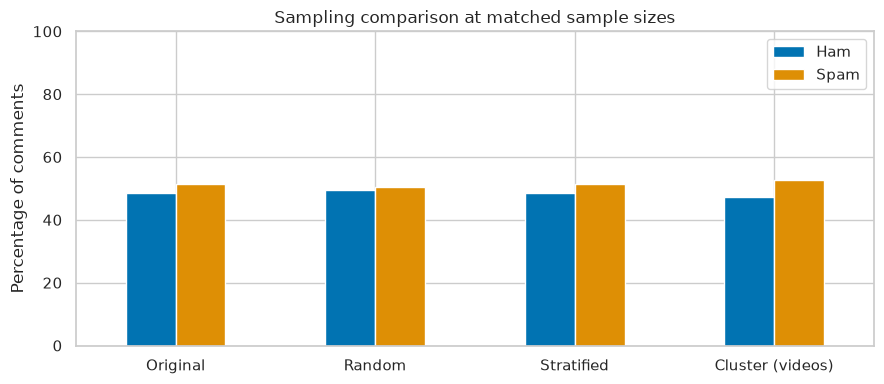

The stratified sample differs from the population spam proportion by **0.05 percentage points**, versus **1.19** for random sampling and **1.21** for cluster sampling. Stratification controls label balance; the other methods do not. Video-level differences affect the cluster sample. One random seed is an illustration, not a proof that one method always has a particular error.

In [5]:
rng = np.random.default_rng(SEED)
selected_videos = sorted(rng.choice(sorted(df['video'].unique()), size=2, replace=False))
cluster_sample = df.loc[df['video'].isin(selected_videos)]
sample_n = len(cluster_sample)
random_sample = df.sample(n=sample_n, random_state=SEED)
stratified_sample, _ = train_test_split(df, train_size=sample_n, stratify=df['label'], random_state=SEED)
samples = {'Original': df, 'Random': random_sample, 'Stratified': stratified_sample,
           'Cluster (videos)': cluster_sample}
sampling_table = pd.DataFrame([
    {'sample': name, 'rows': len(sample),
     'ham_count': int((sample['label'] == 0).sum()),
     'spam_count': int((sample['label'] == 1).sum()),
     'ham_pct': 100 * (sample['label'] == 0).mean(),
     'spam_pct': 100 * (sample['label'] == 1).mean()}
    for name, sample in samples.items()
]).set_index('sample')
display(sampling_table.round(2))
print('Randomly selected video clusters:', ', '.join(selected_videos))
fig, ax = plt.subplots(figsize=(9, 4))
sampling_table[['ham_pct', 'spam_pct']].rename(columns={'ham_pct': 'Ham', 'spam_pct': 'Spam'}).plot.bar(ax=ax)
ax.set(ylabel='Percentage of comments', xlabel='', title='Sampling comparison at matched sample sizes', ylim=(0, 100))
ax.tick_params(axis='x', rotation=0)
save_figure(fig, 'sampling_comparison.png')
deviations = (sampling_table['spam_pct'] - sampling_table.loc['Original', 'spam_pct']).abs()
display(Markdown(
    f"The stratified sample differs from the population spam proportion by **{deviations['Stratified']:.2f} percentage points**, "
    f"versus **{deviations['Random']:.2f}** for random sampling and **{deviations['Cluster (videos)']:.2f}** for cluster sampling. "
    "Stratification controls label balance; the other methods do not. Video-level differences affect the cluster sample. "
    "One random seed is an illustration, not a proof that one method always has a particular error."
))


## 5. Correlation between numerical text features

Pearson correlation summarizes linear association; nonlinear relationships may
remain even when Pearson's coefficient is small. These are derived measurements
of the same comments, so shared definitions can create strong relationships.


,char_count,word_count,unique_word_count,avg_word_length
char_count,1.000,0.904,0.870,-0.024
word_count,0.904,1.000,0.970,-0.127
unique_word_count,0.870,0.970,1.000,-0.152
avg_word_length,-0.024,-0.127,-0.152,1.000


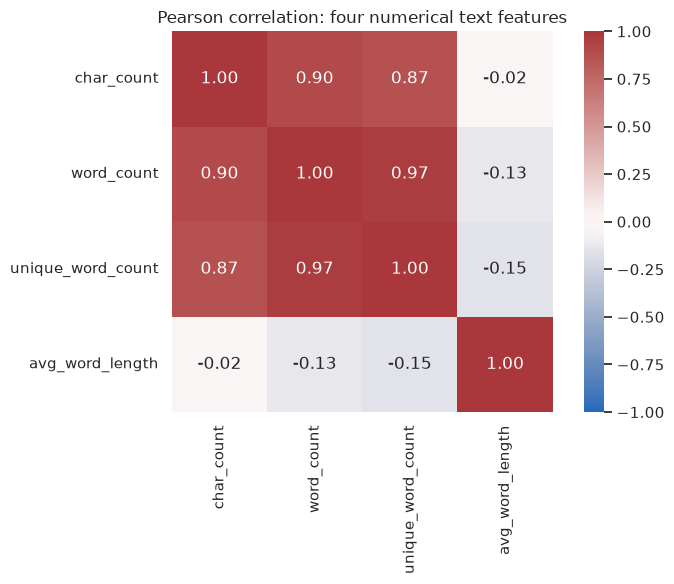

The strongest absolute association is **word_count / unique_word_count**, r = **0.970**; the weakest is **char_count / avg_word_length**, r = **-0.024**. Longer comments often have both more characters and more words, whereas typical token length describes a different aspect of writing. **Correlation does not imply causation:** these measures share their source text and mathematical definitions; the heatmap is observational, not an intervention.

In [6]:
corr = df[TEXT_FEATURES].corr()
display(corr.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Pearson correlation: four numerical text features')
save_figure(fig, 'correlation_heatmap.png')
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strong_pair = pairs.abs().idxmax()
weak_pair = pairs.abs().idxmin()
display(Markdown(
    f"The strongest absolute association is **{strong_pair[0]} / {strong_pair[1]}**, "
    f"r = **{pairs[strong_pair]:.3f}**; the weakest is **{weak_pair[0]} / {weak_pair[1]}**, "
    f"r = **{pairs[weak_pair]:.3f}**. Longer comments often have both more characters and more words, "
    "whereas typical token length describes a different aspect of writing. **Correlation does not imply causation:** "
    "these measures share their source text and mathematical definitions; the heatmap is observational, not an intervention."
))


## 6. Tokenization and word frequencies

Tokenization splits normalized text on whitespace. This transparent baseline
requires no language-model download. English stop words are removed only for
the second exploratory frequency table and for clustering. URL/number markers
are also excluded from lexical charts. Classifiers retain stop words and markers,
since they can carry predictive information. We do not stem or lemmatize words.


Total tokens: 30,821; unique tokens: 3,654
Average words per record: 15.85
English stop words: 46.1% of all tokens


Before removal       After removal      
             word count          word count
0               i   917         check   570
1     numbertoken   902         video   311
2            this   736          song   290
3             the   716          like   249
4             and   639       youtube   247
5              to   634     subscribe   229
6             you   613       channel   198
7             out   582          love   198
8              my   581          just   172
9           check   570         music   156
10              a   559             t   155
11             on   387             m   143
12             it   384             s   130
13             is   332           new   120
14          video   311          guys   119
15             of   310           com   115
16           song   290         views   110
17            for   264         money    91
18             me   251          make    89
19         please   249           hey    87

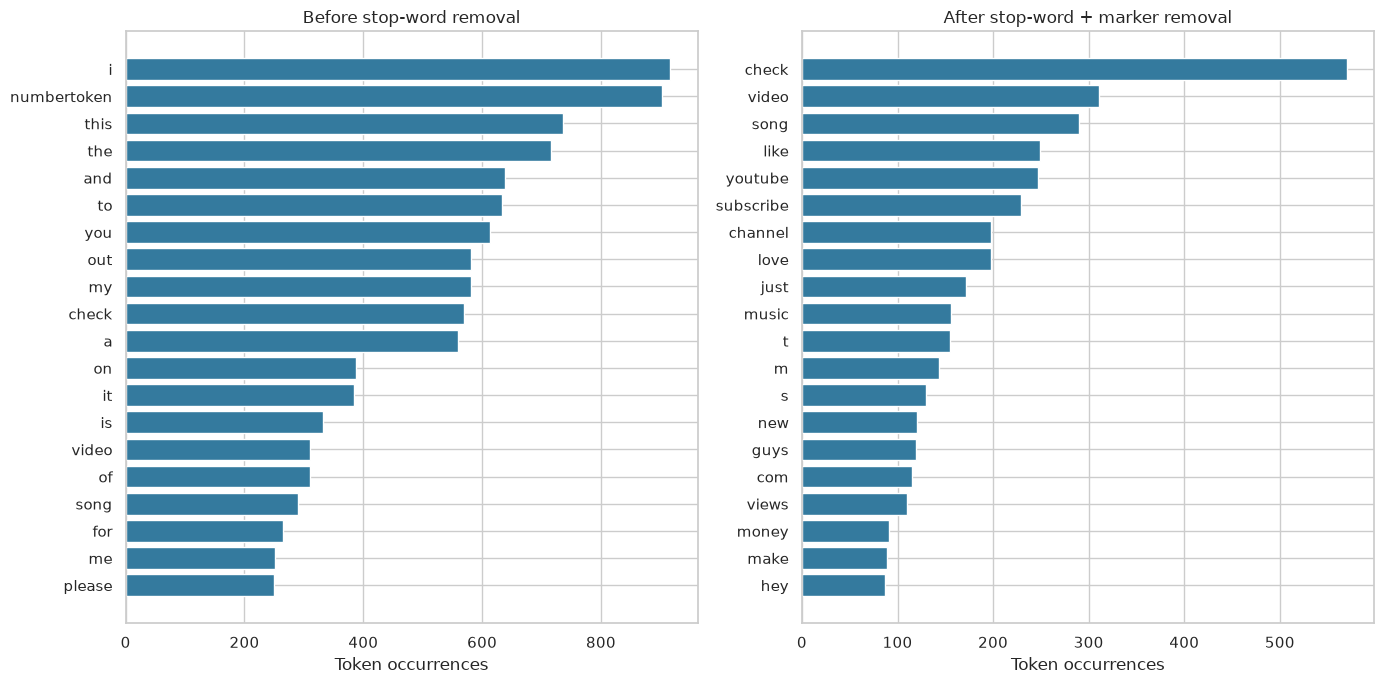

In [7]:
all_tokens = list(chain.from_iterable(token_lists))
counts_before = Counter(all_tokens)
LEXICAL_EXCLUSIONS = set(ENGLISH_STOP_WORDS) | {'urltoken', 'numbertoken'}
lexical_tokens = [word for word in all_tokens if word not in LEXICAL_EXCLUSIONS]
counts_after = Counter(lexical_tokens)
total_tokens = len(all_tokens)
unique_words = len(counts_before)
stopword_share = sum(count for word, count in counts_before.items() if word in ENGLISH_STOP_WORDS) / total_tokens
print(f'Total tokens: {total_tokens:,}; unique tokens: {unique_words:,}')
print(f'Average words per record: {total_tokens / len(df):.2f}')
print(f'English stop words: {stopword_share:.1%} of all tokens')

def frequency_table(counter, n):
    return pd.DataFrame(counter.most_common(n), columns=['word', 'count'])

top20_before = frequency_table(counts_before, 20)
top20_after = frequency_table(counts_after, 20)
display(pd.concat({'Before removal': top20_before, 'After removal': top20_after}, axis=1))
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, table, title in zip(axes, [top20_before, top20_after],
                           ['Before stop-word removal', 'After stop-word + marker removal']):
    ax.barh(table['word'][::-1], table['count'][::-1], color='#347a9e')
    ax.set(title=title, xlabel='Token occurrences')
save_figure(fig, 'word_frequency.png')


### 6.1 Spam-versus-ham comparisons

Compare original character length, normalized word count, and each group's
10 most common non-stop words. Frequencies count token occurrences, not distinct
people. Group sizes and repeated promotional templates influence raw counts.


,records,mean_chars,mean_words,url_rate
label_name,,,,
ham,942,50.054,9.211,0.012
spam,1003,137.497,22.078,0.190


ham             spam      
      word count       word count
0     song   224      check   557
1     love   145  subscribe   228
2     like    90      video   227
3    views    87    youtube   225
4    video    84    channel   197
5     best    57       like   159
6  billion    56       just   128
7     katy    56        new   117
8        s    54      music   117
9     good    48       guys   116

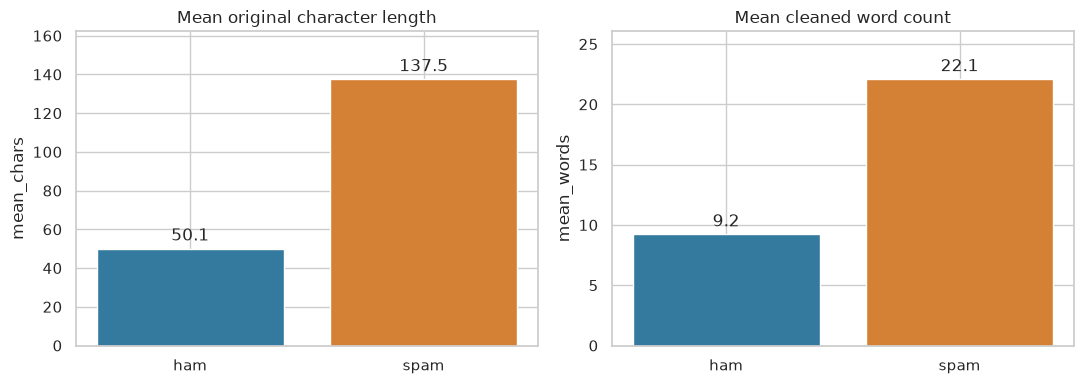

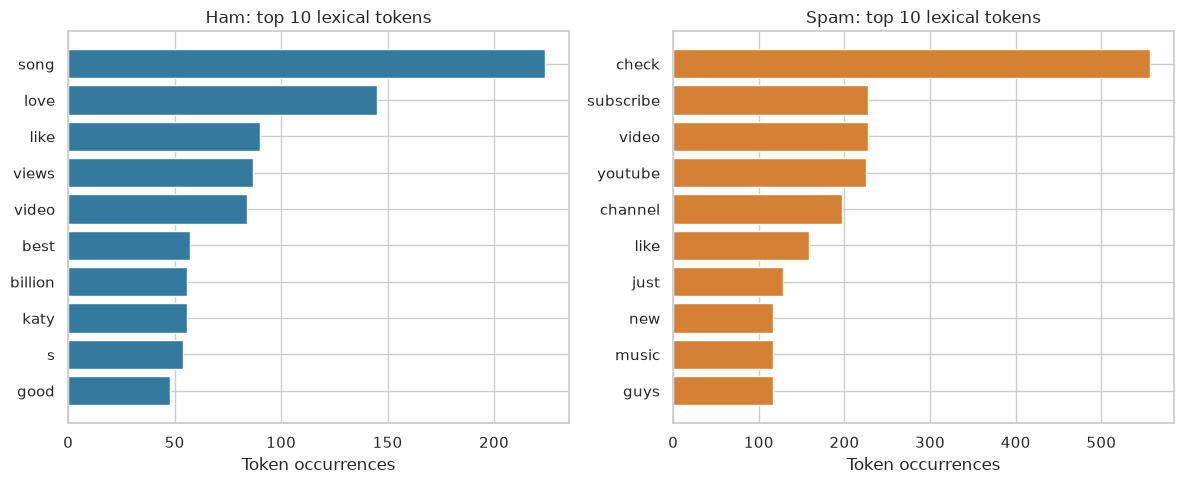

In [8]:
group_stats = df.groupby('label_name', observed=True).agg(
    records=('label', 'size'), mean_chars=('char_count', 'mean'),
    mean_words=('word_count', 'mean'), url_rate=('has_url', 'mean'))
display(group_stats.round(3))
group_counters = {
    name: Counter(word for text in df.loc[df['label_name'] == name, 'cleaned_text']
                  for word in text.split() if word not in LEXICAL_EXCLUSIONS)
    for name in ['ham', 'spam']
}
display(pd.concat({name: frequency_table(counter, 10) for name, counter in group_counters.items()}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, field, title in zip(axes, ['mean_chars', 'mean_words'],
                           ['Mean original character length', 'Mean cleaned word count']):
    values = group_stats.loc[['ham', 'spam'], field]
    bars = ax.bar(values.index.astype(str), values.values, color=['#347a9e', '#d58135'])
    ax.bar_label(bars, fmt='%.1f', padding=3)
    ax.set(title=title, ylabel=field, ylim=(0, values.max() * 1.18))
save_figure(fig, 'group_comparison.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['ham', 'spam']):
    table = frequency_table(group_counters[name], 10)
    ax.barh(table['word'][::-1], table['count'][::-1], color='#347a9e' if name == 'ham' else '#d58135')
    ax.set(title=f'{name.title()}: top 10 lexical tokens', xlabel='Token occurrences')
save_figure(fig, 'group_top_words.png')


### 6.2 Evidence-based insights

Each insight below explicitly separates an observation, numerical evidence, and
interpretation. Values are generated from this execution, rather than copied
from assumed or external benchmark results.


In [9]:
spam_share = df['label'].mean()
video_rates = df.groupby('video')['label'].mean().sort_values()
longer_group = group_stats['mean_chars'].idxmax()
ham_word, ham_frequency = group_counters['ham'].most_common(1)[0]
spam_word, spam_frequency = group_counters['spam'].most_common(1)[0]
insights = f'''
1. **Class balance.** **Observation:** both labels are well represented.
   **Evidence:** {int((df.label == 1).sum()):,} spam and {int((df.label == 0).sum()):,} ham comments
   ({spam_share:.1%} spam). **Interpretation:** accuracy should still be compared
   with a majority baseline; this curated sample does not estimate YouTube's real spam prevalence.
2. **Message length.** **Observation:** {longer_group} comments are longer on average.
   **Evidence:** spam averages {group_stats.loc['spam', 'mean_chars']:.1f} characters and
   {group_stats.loc['spam', 'mean_words']:.1f} words, versus ham's
   {group_stats.loc['ham', 'mean_chars']:.1f} characters and {group_stats.loc['ham', 'mean_words']:.1f} words.
   **Interpretation:** length offers useful descriptive context, but group means
   overlap and do not supply a reliable decision rule for every comment.
3. **Group vocabulary.** **Observation:** the most frequent lexical tokens differ.
   **Evidence:** spam's leading term is **{spam_word}** ({spam_frequency} occurrences),
   while ham's is **{ham_word}** ({ham_frequency} occurrences).
   **Interpretation:** language patterns motivate TF-IDF classification; a frequent
   word is not by itself proof that an individual message is spam.
4. **Links.** **Observation:** URL usage differs between the groups.
   **Evidence:** {group_stats.loc['spam', 'url_rate']:.1%} of spam comments and
   {group_stats.loc['ham', 'url_rate']:.1%} of ham comments contain a detected URL.
   **Interpretation:** a URL marker can capture promotional behavior without
   memorizing domains; legitimate links and link-free spam still require context.
5. **Stop words.** **Observation:** common English function words occupy much of the text.
   **Evidence:** they account for {stopword_share:.1%} of the {total_tokens:,} tokens.
   **Interpretation:** removing them makes exploratory topic charts easier to read,
   but keeping them in the classifier permits useful phrase patterns.
6. **Source variation.** **Observation:** video groups have different spam proportions.
   **Evidence:** rates range from {video_rates.iloc[0]:.1%} for {video_rates.index[0]}
   to {video_rates.iloc[-1]:.1%} for {video_rates.index[-1]}.
   **Interpretation:** selecting whole videos can shift a sample's label mix;
   this motivates reporting sampling distributions and caution about unseen videos.
'''
display(Markdown(insights))
(OUTPUT / 'text_insights.md').write_text(insights.strip() + '\n')



1. **Class balance.** **Observation:** both labels are well represented.
   **Evidence:** 1,003 spam and 942 ham comments
   (51.6% spam). **Interpretation:** accuracy should still be compared
   with a majority baseline; this curated sample does not estimate YouTube's real spam prevalence.
2. **Message length.** **Observation:** spam comments are longer on average.
   **Evidence:** spam averages 137.5 characters and
   22.1 words, versus ham's
   50.1 characters and 9.2 words.
   **Interpretation:** length offers useful descriptive context, but group means
   overlap and do not supply a reliable decision rule for every comment.
3. **Group vocabulary.** **Observation:** the most frequent lexical tokens differ.
   **Evidence:** spam's leading term is **check** (557 occurrences),
   while ham's is **song** (224 occurrences).
   **Interpretation:** language patterns motivate TF-IDF classification; a frequent
   word is not by itself proof that an individual message is spam.
4. **Links.** **Observation:** URL usage differs between the groups.
   **Evidence:** 19.0% of spam comments and
   1.2% of ham comments contain a detected URL.
   **Interpretation:** a URL marker can capture promotional behavior without
   memorizing domains; legitimate links and link-free spam still require context.
5. **Stop words.** **Observation:** common English function words occupy much of the text.
   **Evidence:** they account for 46.1% of the 30,821 tokens.
   **Interpretation:** removing them makes exploratory topic charts easier to read,
   but keeping them in the classifier permits useful phrase patterns.
6. **Source variation.** **Observation:** video groups have different spam proportions.
   **Evidence:** rates range from 47.4% for Shakira
   to 54.9% for Eminem.
   **Interpretation:** selecting whole videos can shift a sample's label mix;
   this motivates reporting sampling distributions and caution about unseen videos.


1939

## 7. Supervised text classification

### 7.1 A leakage-aware stratified train/test split

Use the first fold of a seeded, shuffled **five-fold StratifiedGroupKFold** as an
approximately 20% holdout. This is one fixed train/test split, not a claim of
cross-validation performance. Stratification approximates the class proportions;
grouping keeps **all identical cleaned messages in one partition**. Group sizes
mean the split need not be exactly 80/20. We do not choose a fold based on scores.

This is stronger than randomly splitting duplicated text. It does not guarantee
that near-duplicates, the same author, or the same video never span partitions;
cross-video generalization remains an important limitation.


In [10]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df['cleaned_text'], df['label'], groups=df['cleaned_text']))
train = df.iloc[train_idx]
test = df.iloc[test_idx]
assert set(train['cleaned_text']).isdisjoint(set(test['cleaned_text']))
assert set(train['COMMENT_ID']).isdisjoint(set(test['COMMENT_ID']))
assert set(train['label']) == set(test['label']) == {0, 1}
split_distribution = pd.DataFrame({
    name: {'rows': len(frame), 'spam_pct': 100 * frame['label'].mean(),
           'unique_texts': frame['cleaned_text'].nunique()}
    for name, frame in [('All', df), ('Train', train), ('Test', test)]
}).T
display(split_distribution.round(2))
print('Overlapping cleaned-text groups between train and test: 0')
df['split'] = 'train'
df.loc[test_idx, 'split'] = 'test'


,rows,spam_pct,unique_texts
All,1945.0,51.57,1604.0
Train,1556.0,51.54,1339.0
Test,389.0,51.67,265.0


Overlapping cleaned-text groups between train and test: 0


### 7.2 TF-IDF and two classifiers (model-extension bonus)

TF-IDF weights a term by its frequency in a document and its rarity across the
training corpus. Each pipeline **fits its vocabulary and IDF only on training
text**, then transforms test text. Unigrams and bigrams capture words and short
phrases such as "check out". `min_df=2` reduces one-off vocabulary noise.

Compare Multinomial Naive Bayes (a fast nonnegative-feature baseline) with Logistic
Regression (a linear discriminative classifier) on the **same held-out rows**.
Hyperparameters are fixed in advance; there is no test-set tuning. Include a
majority-class dummy baseline for context. Label 1 (spam) is the positive class.

- Accuracy: fraction of all predictions that are correct.
- Precision: among predicted spam, how many are spam?
- Recall: among actual spam, how many are detected?
- F1: harmonic mean of precision and recall.
- Macro F1: average of the two class-specific F1 scores, weighting classes equally.


Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham     0.9600    0.8936    0.9256       188
        spam     0.9065    0.9652    0.9349       201

    accuracy                         0.9306       389
   macro avg     0.9333    0.9294    0.9303       389
weighted avg     0.9324    0.9306    0.9304       389

Logistic Regression
              precision    recall  f1-score   support

         ham     0.9424    0.9574    0.9499       188
        spam     0.9596    0.9453    0.9524       201

    accuracy                         0.9512       389
   macro avg     0.9510    0.9514    0.9511       389
weighted avg     0.9513    0.9512    0.9512       389



,accuracy,precision_spam,recall_spam,f1_spam,f1_macro
model,,,,,
Multinomial Naive Bayes,0.9306,0.9065,0.9652,0.9349,0.9303
Logistic Regression,0.9512,0.9596,0.9453,0.9524,0.9511


Majority-class baseline accuracy: 0.5167


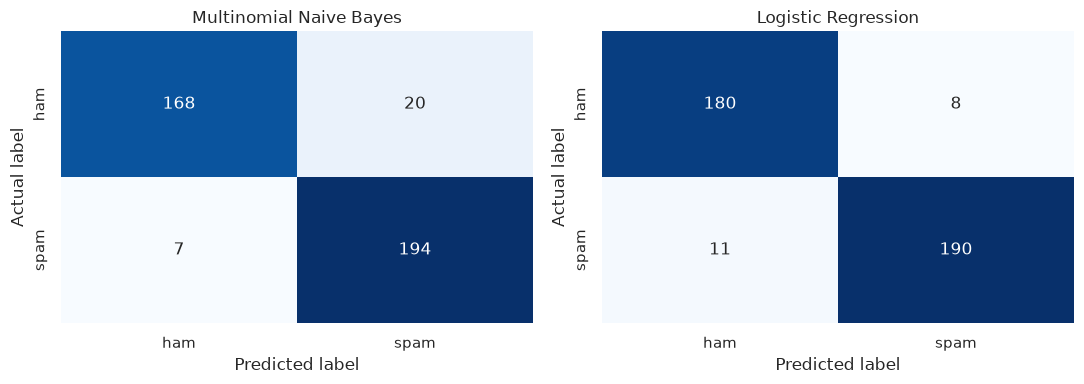

In [11]:
estimators = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=1.0),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
}
pipelines, predictions, metric_rows, report_sections = {}, {}, [], []
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(np.zeros((len(train), 1)), train['label'])
baseline_prediction = baseline.predict(np.zeros((len(test), 1)))
baseline_accuracy = accuracy_score(test['label'], baseline_prediction)
for name, classifier in estimators.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, sublinear_tf=True)),
        ('classifier', classifier),
    ])
    pipeline.fit(train['cleaned_text'], train['label'])
    prediction = pipeline.predict(test['cleaned_text'])
    pipelines[name] = pipeline
    predictions[name] = prediction
    metric_rows.append({
        'model': name, 'accuracy': accuracy_score(test['label'], prediction),
        'precision_spam': precision_score(test['label'], prediction, zero_division=0),
        'recall_spam': recall_score(test['label'], prediction, zero_division=0),
        'f1_spam': f1_score(test['label'], prediction, zero_division=0),
        'f1_macro': f1_score(test['label'], prediction, average='macro', zero_division=0),
    })
    report = classification_report(test['label'], prediction, labels=[0, 1],
                                   target_names=['ham', 'spam'], digits=4, zero_division=0)
    report_sections.append(name + '\n' + report + '\nConfusion matrix (rows actual, columns predicted; ham, spam):\n'
                           + str(confusion_matrix(test['label'], prediction, labels=[0, 1])))
    print(name + '\n' + report)

metrics = pd.DataFrame(metric_rows).set_index('model')
display(metrics.round(4))
print(f'Majority-class baseline accuracy: {baseline_accuracy:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, prediction) in zip(axes, predictions.items()):
    matrix = confusion_matrix(test['label'], prediction, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax)
    ax.set(title=name, xlabel='Predicted label', ylabel='Actual label')
save_figure(fig, 'confusion_matrices.png')


In [12]:
best_model = metrics['f1_macro'].idxmax()
winner = metrics.loc[best_model]
display(Markdown(
    f"**{best_model}** has the higher observed macro F1 (**{winner['f1_macro']:.3f}**) on this fixed split, "
    f"with accuracy **{winner['accuracy']:.3f}**, compared with **{baseline_accuracy:.3f}** for the majority baseline. "
    f"Its spam precision is **{winner['precision_spam']:.3f}** and recall **{winner['recall_spam']:.3f}**. "
    "False positives would hide legitimate comments; false negatives would leave spam visible. "
    "The score difference is descriptive, not a statistical significance claim, and the higher-scoring model was not retuned using this test set. "
    "**Limitations:** only five older music videos, curated class proportions, residual near-duplicate/author overlap, "
    "loss of punctuation and exact URLs, and a single modest-sized holdout. A separate video-level holdout and repeated grouped "
    "cross-validation would provide stronger evidence about generalization."
))
metrics_text = (
    'CSCI461 Assignment 1 — supervised classification\n'
    f'Dataset SHA-256: {provenance["dataset_sha256"]}\n'
    f'Seed: {SEED}; train rows: {len(train)}; test rows: {len(test)}\n'
    'Split: first seeded StratifiedGroupKFold(5) fold; groups = cleaned_text\n'
    'Overlapping cleaned-text groups: 0; TF-IDF fitted on training rows only.\n'
    'TF-IDF: unigrams+bigrams, min_df=2, max_features=20000, sublinear_tf=True\n'
    'MultinomialNB alpha=1.0; LogisticRegression max_iter=2000, random_state=42\n'
    f'Majority baseline accuracy: {baseline_accuracy:.6f}\n\n'
    + metrics.to_string(float_format=lambda value: f'{value:.6f}') + '\n\n'
    + '\n\n'.join(report_sections)
    + '\n\nLimitations: single holdout; old, curated, five-video corpus; near-duplicate and author overlap may remain.\n'
)
(OUTPUT / 'model_metrics.txt').write_text(metrics_text)


**Logistic Regression** has the higher observed macro F1 (**0.951**) on this fixed split, with accuracy **0.951**, compared with **0.517** for the majority baseline. Its spam precision is **0.960** and recall **0.945**. False positives would hide legitimate comments; false negatives would leave spam visible. The score difference is descriptive, not a statistical significance claim, and the higher-scoring model was not retuned using this test set. **Limitations:** only five older music videos, curated class proportions, residual near-duplicate/author overlap, loss of punctuation and exact URLs, and a single modest-sized holdout. A separate video-level holdout and repeated grouped cross-validation would provide stronger evidence about generalization.

1813

## 8. Unsupervised K-Means clustering

Clustering asks which comments have similar language, **without fitting on spam
labels**. Use a separate TF-IDF representation with stop words/markers removed,
then 50-dimensional TruncatedSVD and L2 normalization. SVD reduces sparse noise
and computation; normalization limits document-length effects. Record the
retained variance because dimensionality reduction can discard information.

Comments with no retained vocabulary are excluded from clustering and assigned
`cluster = -1` in the CSV; their original records remain in the analysis and
classification. Evaluate **k = 2 through 6**, encompassing two labels, five video
sources, and a possible extra linguistic theme. Select the highest sampled
Euclidean silhouette score in the same normalized representation used by K-Means.
The choice is exploratory, is not forced to 3, and does not use known labels.

Silhouette compares within-cluster compactness to nearest-other-cluster separation
and ranges from -1 to 1. Higher is better, but a high score alone cannot establish
semantic usefulness. Examine sizes, terms, and representative comments as well.


,k,silhouette,inertia,smallest_cluster
0,2,0.0737,1603.6505,152
1,3,0.0896,1534.5996,149
2,4,0.1069,1467.9199,147
3,5,0.1140,1425.5075,135
4,6,0.1280,1383.2520,106


Chosen k: 6; silhouette: 0.1280; scored sample: 1500
SVD dimensions: 50; retained variance: 38.6%
Clustered comments: 1840; no-retained-vocabulary comments: 105


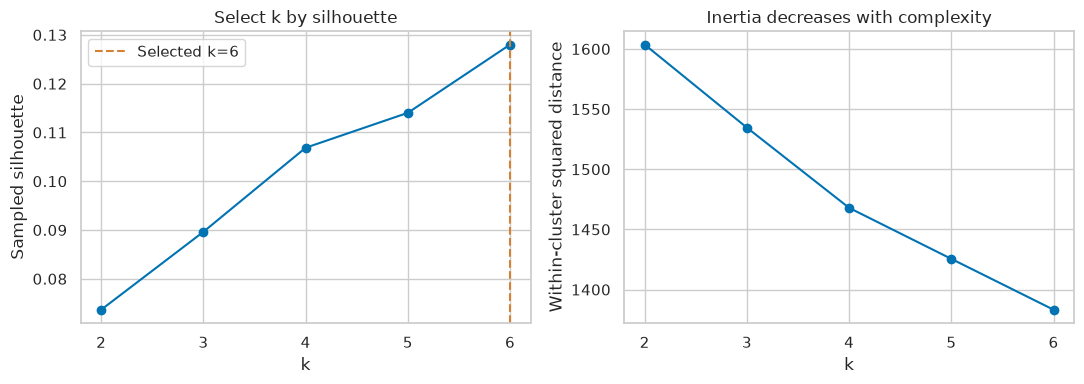

In [13]:
cluster_vectorizer = TfidfVectorizer(stop_words=sorted(LEXICAL_EXCLUSIONS), ngram_range=(1, 2),
                                    min_df=2, max_df=0.90, max_features=10000, sublinear_tf=True)
cluster_tfidf = cluster_vectorizer.fit_transform(df['cleaned_text'])
eligible = np.asarray(cluster_tfidf.getnnz(axis=1) > 0)
eligible_idx = np.flatnonzero(eligible)
X_cluster = cluster_tfidf[eligible]
components = min(50, X_cluster.shape[0] - 1, X_cluster.shape[1] - 1)
svd = TruncatedSVD(n_components=components, random_state=SEED)
Z = normalize(svd.fit_transform(X_cluster))
silhouette_n = min(1500, len(Z))
k_models, k_rows = {}, []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    assignments = model.fit_predict(Z)
    score = silhouette_score(Z, assignments, metric='euclidean', sample_size=silhouette_n, random_state=SEED)
    k_models[k] = model
    k_rows.append({'k': k, 'silhouette': score, 'inertia': model.inertia_,
                   'smallest_cluster': int(np.bincount(assignments).min())})
k_experiment = pd.DataFrame(k_rows)
best_k = int(k_experiment.loc[k_experiment['silhouette'].idxmax(), 'k'])
kmeans = k_models[best_k]
cluster_labels = kmeans.labels_
best_silhouette = float(k_experiment.set_index('k').loc[best_k, 'silhouette'])
df['cluster'] = -1
df.loc[eligible_idx, 'cluster'] = cluster_labels
display(k_experiment.round(4))
print(f'Chosen k: {best_k}; silhouette: {best_silhouette:.4f}; scored sample: {silhouette_n}')
print(f'SVD dimensions: {components}; retained variance: {svd.explained_variance_ratio_.sum():.1%}')
print(f'Clustered comments: {len(Z)}; no-retained-vocabulary comments: {(~eligible).sum()}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_experiment['k'], k_experiment['silhouette'], marker='o')
axes[0].axvline(best_k, color='#d58135', linestyle='--', label=f'Selected k={best_k}')
axes[0].set(xlabel='k', ylabel='Sampled silhouette', title='Select k by silhouette', xticks=range(2, 7))
axes[0].legend()
axes[1].plot(k_experiment['k'], k_experiment['inertia'], marker='o')
axes[1].set(xlabel='k', ylabel='Within-cluster squared distance', title='Inertia decreases with complexity', xticks=range(2, 7))
save_figure(fig, 'cluster_selection.png')


### 8.1 Cluster sizes, representative terms, and interpretation

Top terms are ranked by **mean original TF-IDF within each cluster**, making the
reduced-space solution interpretable. Representative comments are the two nearest
to each normalized-SVD centroid. Labels are introduced only now, for external
comparison. A cluster ID is an arbitrary index, not a ham/spam class ID.


,cluster,records,spam_share,top_terms,interpretation
0,0,106,0.103774,"[views, billion, billion views, million, video, came, check views, reach, people, views million]","View counts, popularity, and suspected view inflation; the representatives discuss billions of v..."
1,1,168,0.994048,"[subscribe, subscribe channel, channel, like, videos, guys, like subscribe, subscribe like, plz,...",Direct requests for subscriptions and channel engagement; the representatives are short self-pro...
2,2,200,0.925000,"[youtube, check video, video youtube, check, video, playlist youtube, check playlist, playlist, ...","Cross-video or playlist promotion, especially repeated check-out-this-video templates."
3,3,1063,0.502352,"[like, check, channel, music, good, shakira, just, best, video, comment]",Broad mixed music discussion and self-promotion; no single clean topic. Representatives include ...
4,4,165,0.157576,"[song, best song, best, like song, like, good, nice song, nice, old, good song]","Song-centered opinions, praise, and discovery, rather than explicit subscription requests."
5,5,138,0.115942,"[love, love song, song, shakira, love shakira, love katy, katy, perry, katy perry, songs]","Fan affection for songs and artists, including Shakira and Katy Perry."


Cluster 0:
   to everyone joking about how he hacked to get numbertoken billion views because there s a certain amount of people or whatever he actually did buy views
   the funny thing is numbertoken numbertoken numbertoken numbertoken of the views are spam bots i mean c mon numbertoken billion views bs
Cluster 1:
   subscribe me
   please subscribe me
Cluster 2:
   check out this video on youtube looking for my wood pile anyone seen it hmm how bout some pie now ladies
   check out this video on youtube
Cluster 3:
   hey i know most people don t like these kind of comments see at spam but i see as free advertising so please check out my cover of sparks fly by taylor swift it is not the best eve
   hey everyone please take a moment to read this i work my ass off hoping to make it into the music industry but its hard to get people to hear you when you don t have money for adve
Cluster 4:
   this song is special because is a song for africa and i am an african
   i found out this song no

label_name,ham,spam
cluster,,
0,95,11
1,1,167
2,15,185
3,529,534
4,139,26
5,122,16


label_name,ham,spam
cluster,,
0,0.896,0.104
1,0.006,0.994
2,0.075,0.925
3,0.498,0.502
4,0.842,0.158
5,0.884,0.116


Adjusted Rand index against known labels (external comparison only): 0.0507


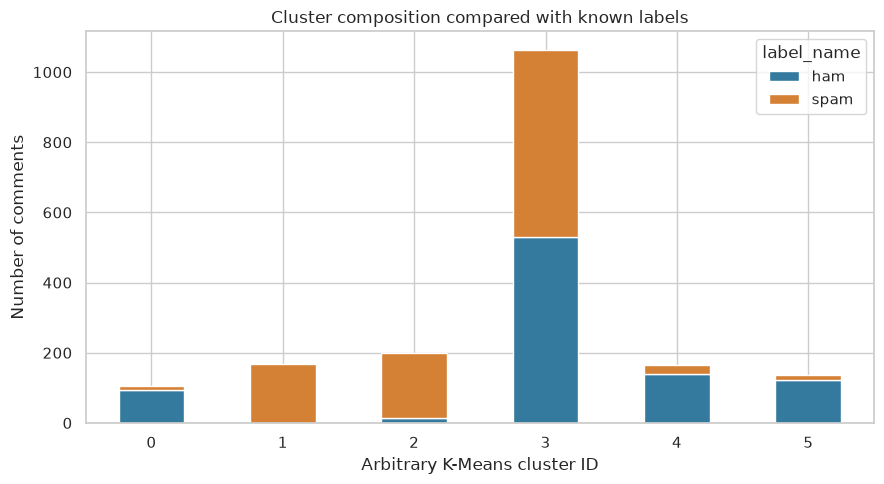

The selected **k=6** solution has silhouette **0.128** and adjusted Rand index **0.051**. Its largest cluster holds **57.8%** of eligible comments. Here the low silhouette and large mixed cluster indicate **weak overall separation**, despite several recognizable phrase themes. The crosstab reveals whether clusters are label-dominated or mixed; it does not turn cluster IDs into predictions. Text similarity can follow shared phrases, artists, or promotional templates rather than the spam distinction. ARI measures label agreement after accounting for chance and is invariant to renaming cluster IDs. A low agreement is compatible with useful topic clusters. The limited k range, SVD information loss, and K-Means' preference for roughly spherical groups limit this exploratory result. The best k is at the upper boundary of the tested range, so it is only the best of these five candidates, not a global optimum.

3861

In [14]:
terms = cluster_vectorizer.get_feature_names_out()
# Human interpretations reviewed against this run's top terms and nearest comments.
# Key by the leading term rather than treating arbitrary cluster IDs as semantics.
reviewed_themes = {
    'views': 'View counts, popularity, and suspected view inflation; the representatives discuss billions of views.',
    'subscribe': 'Direct requests for subscriptions and channel engagement; the representatives are short self-promotion.',
    'youtube': 'Cross-video or playlist promotion, especially repeated check-out-this-video templates.',
    'like': 'Broad mixed music discussion and self-promotion; no single clean topic. Representatives include aspiring musicians advertising covers.',
    'song': 'Song-centered opinions, praise, and discovery, rather than explicit subscription requests.',
    'love': 'Fan affection for songs and artists, including Shakira and Katy Perry.',
}
cluster_records = []
for cluster_id in range(best_k):
    mask = cluster_labels == cluster_id
    mean_weights = np.asarray(X_cluster[mask].mean(axis=0)).ravel()
    top_terms = terms[mean_weights.argsort()[-10:][::-1]].tolist()
    member_positions = np.flatnonzero(mask)
    distances = np.linalg.norm(Z[mask] - kmeans.cluster_centers_[cluster_id], axis=1)
    nearest = member_positions[np.argsort(distances)[:2]]
    representatives = [df.iloc[eligible_idx[pos]]['cleaned_text'][:180] for pos in nearest]
    cluster_records.append({
        'cluster': cluster_id, 'records': int(mask.sum()),
        'spam_share': float(df.iloc[eligible_idx[mask]]['label'].mean()),
        'top_terms': top_terms, 'representatives': representatives,
        'interpretation': reviewed_themes.get(top_terms[0],
            'Unreviewed theme around ' + ', '.join(top_terms[:5]) + '; inspect the representative comments.'),
    })
display(pd.DataFrame(cluster_records)[['cluster', 'records', 'spam_share', 'top_terms', 'interpretation']])
for record in cluster_records:
    print(f'Cluster {record["cluster"]}:')
    for text in record['representatives']:
        print('  ', text)

label_cross_tab = pd.crosstab(df.loc[eligible, 'cluster'], df.loc[eligible, 'label_name'])
display(label_cross_tab)
display(label_cross_tab.div(label_cross_tab.sum(axis=1), axis=0).round(3))
ari = adjusted_rand_score(df.loc[eligible, 'label'], cluster_labels)
print(f'Adjusted Rand index against known labels (external comparison only): {ari:.4f}')
fig, ax = plt.subplots(figsize=(9, 5))
label_cross_tab[['ham', 'spam']].plot.bar(stacked=True, ax=ax, color=['#347a9e', '#d58135'])
ax.set(xlabel='Arbitrary K-Means cluster ID', ylabel='Number of comments', title='Cluster composition compared with known labels')
ax.tick_params(axis='x', rotation=0)
save_figure(fig, 'clusters_by_label.png')
display(Markdown(
    f"The selected **k={best_k}** solution has silhouette **{best_silhouette:.3f}** and adjusted Rand index **{ari:.3f}**. "
    f"Its largest cluster holds **{max(record['records'] for record in cluster_records) / len(Z):.1%}** of eligible comments. "
    "Here the low silhouette and large mixed cluster indicate **weak overall separation**, despite several recognizable phrase themes. "
    "The crosstab reveals whether clusters are label-dominated or mixed; it does not turn cluster IDs into predictions. "
    "Text similarity can follow shared phrases, artists, or promotional templates rather than the spam distinction. "
    "ARI measures label agreement after accounting for chance and is invariant to renaming cluster IDs. "
    "A low agreement is compatible with useful topic clusters. The limited k range, SVD information loss, "
    "and K-Means' preference for roughly spherical groups limit this exploratory result. "
    "The best k is at the upper boundary of the tested range, so it is only the best of these five candidates, not a global optimum."
))

cluster_text = (
    'CSCI461 Assignment 1 — K-Means clustering\n'
    f'Eligible records: {len(Z)}; excluded empty-vocabulary records (cluster=-1): {int((~eligible).sum())}\n'
    f'Representation: TF-IDF -> TruncatedSVD({components}) -> L2 normalization\n'
    f'SVD explained variance: {svd.explained_variance_ratio_.sum():.6f}\n'
    f'k selection: highest Euclidean silhouette among 2..6; selected k={best_k}\n'
    f'Silhouette: {best_silhouette:.6f}; sample size: {silhouette_n}; random_state: {SEED}\n'
    f'Adjusted Rand index versus labels: {ari:.6f} (not used to fit or select k)\n\n'
    + k_experiment.to_string(index=False) + '\n\n'
)
for record in cluster_records:
    cluster_text += (
        f'Cluster {record["cluster"]}: {record["records"]} records; spam share={record["spam_share"]:.2%}\n'
        + 'Top terms: ' + ', '.join(record['top_terms']) + '\n'
        + 'Interpretation: ' + record['interpretation'] + '\n'
        + 'Representatives: ' + ' | '.join(record['representatives']) + '\n\n'
    )
cluster_text += 'Known-label counts (cluster IDs are not class IDs):\n' + label_cross_tab.to_string() + '\n'
cluster_text += ('\nInterpretation of quality: silhouette near 0.13 and ARI near 0.05 indicate weak overall separation and label agreement. '
                 'The largest cluster is mixed; subscription and video-promotion clusters are spam-heavy, while views/song/affection clusters are ham-heavy. '
                 'k=6 is the upper boundary of the experiment, not an established global optimum.\n')
(OUTPUT / 'cluster_summary.txt').write_text(cluster_text)


## 9. Export and verify the persistent deliverables

Everything below is saved under `output/`, which the Docker run command bind-mounts
to the host. `cleaned_data.csv` preserves original `CONTENT` and adds normalized
text, features, split membership, and cluster assignments. The original dataset
is never overwritten. Assertions check preservation, disjoint text groups, record
accounting, required figures, and valid metrics before declaring success.

Removing the container does not remove these host files. See the README for the
separate fresh-container reproduction and container-removal persistence checks.


In [15]:
df.to_csv(OUTPUT / 'cleaned_data.csv', index=False)
test_predictions = test[['COMMENT_ID', 'source_row', 'label']].copy()
for name, prediction in predictions.items():
    test_predictions[name] = prediction
test_predictions.to_csv(OUTPUT / 'test_predictions.csv', index=False)
sampling_table.to_csv(OUTPUT / 'sampling_distributions.csv')
metrics.to_csv(OUTPUT / 'model_comparison.csv')
k_experiment.to_csv(OUTPUT / 'k_experiment.csv', index=False)
required_figures = ['correlation_heatmap.png', 'word_frequency.png', 'group_comparison.png', 'confusion_matrices.png']
assert all((FIGURES / name).is_file() and (FIGURES / name).stat().st_size > 1000 for name in required_figures)
assert not df[['cleaned_text', 'label', *TEXT_FEATURES]].isna().any().any()
assert sum(record['records'] for record in cluster_records) + int((~eligible).sum()) == len(df)
assert metrics.ge(0).all().all() and metrics.le(1).all().all()
assert df.groupby('cleaned_text')['split'].nunique().max() == 1
assert len(train) + len(test) == len(df)

summary = {
    'dataset_sha256': provenance['dataset_sha256'], 'random_seed': SEED,
    'executed_in_container': in_container, 'package_versions': environment,
    'raw_rows': len(raw), 'cleaned_rows': len(df), 'exact_duplicates': exact_duplicates,
    'duplicate_ids': duplicate_ids, 'repeated_text_rows_raw': repeated_text_rows,
    'invalid_rows': invalid_rows, 'empty_cleaned_rows': empty_cleaned,
    'missing_dates_raw': int(missing_before['DATE']),
    'missing_dates_cleaned': int(df['parsed_date'].isna().sum()),
    'train_rows': len(train), 'test_rows': len(test), 'text_group_overlap': 0,
    'majority_baseline_accuracy': float(baseline_accuracy), 'models': metric_rows,
    'total_tokens': total_tokens, 'unique_tokens': unique_words,
    'selected_videos_for_sampling': selected_videos,
    'k_experiment': k_rows, 'selected_k': best_k, 'silhouette': best_silhouette,
    'silhouette_sample_size': silhouette_n, 'adjusted_rand_index': float(ari),
    'clustered_rows': len(Z), 'unclustered_rows': int((~eligible).sum()),
    'svd_explained_variance': float(svd.explained_variance_ratio_.sum()),
    'clusters': cluster_records, 'figures': sorted(path.name for path in FIGURES.glob('*.png')),
}
(OUTPUT / 'run_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
print('SUCCESS: all analysis, modeling, exports, and notebook assertions completed inside Docker.')
print(f'{len(df):,} cleaned records | {len(train)} train / {len(test)} test | {len(summary["figures"])} saved figures')
for path in sorted(OUTPUT.iterdir()):
    print(path.name + ('/' if path.is_dir() else f' ({path.stat().st_size:,} bytes)'))


SUCCESS: all analysis, modeling, exports, and notebook assertions completed inside Docker.
1,945 cleaned records | 1556 train / 389 test | 8 saved figures
cleaned_data.csv (666,708 bytes)
cluster_summary.txt (3,863 bytes)
figures/
k_experiment.csv (262 bytes)
model_comparison.csv (292 bytes)
model_metrics.txt (1,815 bytes)
run_summary.json (6,427 bytes)
sampling_distributions.csv (291 bytes)
test_predictions.csv (18,563 bytes)
text_insights.md (1,939 bytes)


## 10. Conclusions and discussion preparation

The collection supports a complete text-analysis workflow with auditable cleaning,
natural video-level sampling groups, supervised spam detection, and unsupervised
language clusters. Read the measured scores and cluster descriptions above,
including their limitations, rather than treating this small corpus as a
production benchmark.

Before the team discussion, each member should be able to change a sampling seed,
explain the duplicate-aware split, trace a sentence through TF-IDF, read a
confusion matrix, and explain why cluster IDs are not labels. Also rehearse the
Dockerfile → image → container → registry workflow, ports, layers, bind mounts,
and the reproduction commands in the README and `docs/DISCUSSION_GUIDE.md`.

**External completion requirement:** a different teammate must pull the published
Docker Hub image, execute this notebook successfully, and record their real
verification evidence. The author-machine tests cannot substitute for that step.
